# Historical research notebook
Original calculations and saved outputs are retained. See [experiment notes](../../docs/EXPERIMENT_NOTES.md) before interpreting results.


In [ ]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "VB_FTRL.py").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Start Jupyter from within the repository")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))


CREDIT : This code was copied from https://github.com/andrewcharlesjones/universal_portfolios/blob/master/

In [35]:
# Importing modules 

import numpy as np
import numpy.random as rd
import matplotlib.pyplot as plt
import itertools
import yfinance as yf


In this Notebook, we would like to implement Universal Portfolios.   
We know that we need to compute an integral over $\Delta_d$ where $d$ is the number of assets, so the computation time will be a problem.   
Question : can we try a Monte-Carlo algorithm in order to compute this integral ? 


In [36]:
### GET STOCK DATA

tickers = ['AAPL', 'TSLA', 'KO', 'WBA', 'WMT'] #, 'JCP', 'DKS', 'GOOGL', 'MSFT', 'TWTR']
num_stocks = len(tickers)

data_mat = []

for ticker in tickers:
    data = yf.download(ticker, '2016-01-01', '2018-01-01') #,'2018-01-01')
    data_mat.append(data.Close.values / data.Open.values)
    
data = np.array(data_mat)

Failed to get ticker 'AAPL' reason: Expecting value: line 1 column 1 (char 0)
[*********************100%%**********************]  1 of 1 completed

1 Failed download:
['AAPL']: YFTzMissingError('$%ticker%: possibly delisted; No timezone found')
Failed to get ticker 'TSLA' reason: Expecting value: line 1 column 1 (char 0)
[*********************100%%**********************]  1 of 1 completed

1 Failed download:
['TSLA']: YFTzMissingError('$%ticker%: possibly delisted; No timezone found')
Failed to get ticker 'KO' reason: Expecting value: line 1 column 1 (char 0)
[*********************100%%**********************]  1 of 1 completed

1 Failed download:
['KO']: YFTzMissingError('$%ticker%: possibly delisted; No timezone found')
Failed to get ticker 'WBA' reason: Expecting value: line 1 column 1 (char 0)
[*********************100%%**********************]  1 of 1 completed

1 Failed download:
['WBA']: YFTzMissingError('$%ticker%: possibly delisted; No timezone found')
Failed to get ticker 'WMT'

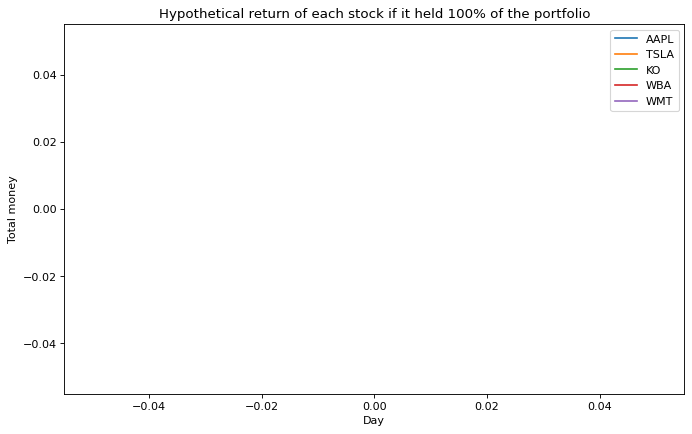

In [37]:
# Get hypothetical returns of each stock if that stock got all the money

initial_money = 1 # start with $1
overall_returns = initial_money * np.cumprod(data, axis=1)

plt.figure(num=None, figsize=(10, 6), dpi=80, facecolor='w', edgecolor='k')
for ii in range(data.shape[0]):
    plt.plot(overall_returns[ii, :], label = tickers[ii])
plt.legend()
plt.xlabel("Day")
plt.ylabel("Total money")
plt.title("Hypothetical return of each stock if it held 100% of the portfolio")
#plt.savefig("./unistock_portfolio_returns.pdf")
plt.show()

In [38]:
# gets the total return for a given portfolio b
def portfolio_wealth(b, stock_data):
    return np.sum(10*np.log(np.dot(b, stock_data)))      # lambda = 10

# function for retrieving all possible portfolios at a certain level of granularity
def binnings(n, k, cache={}):
    if n == 0:
        return np.zeros((1, k))
    if k == 0:
        return np.empty((0, 0))
    args = (n, k)
    if args in cache:
        return cache[args]
    a = binnings(n - 1, k, cache)
    a1 = a + (np.arange(k) == 0)
    b = binnings(n, k - 1, cache)
    b1 = np.hstack((np.zeros((b.shape[0], 1)), b))
    result = np.vstack((a1, b1))
    cache[args] = result
    return result

In [39]:
## COMPUTE ALL POSSIBLE PORTFOLIOS

# Ici on va discretiser notre intégrale, donc on prend différents portefeuilles qui couvrent à peu près Delta_d-1

allocation_granularity = 20
all_portfolio_allocations = binnings(allocation_granularity, num_stocks)
row_sums = all_portfolio_allocations.sum(axis=1)
all_portfolios = all_portfolio_allocations / row_sums[:, np.newaxis]

In [40]:
print(all_portfolios)
len(all_portfolios)

[[1.   0.   0.   0.   0.  ]
 [0.95 0.05 0.   0.   0.  ]
 [0.95 0.   0.05 0.   0.  ]
 ...
 [0.   0.   0.   0.1  0.9 ]
 [0.   0.   0.   0.05 0.95]
 [0.   0.   0.   0.   1.  ]]


10626

In [41]:
## RUN UNIVERSAL PORTFOLIO

initial_money = 1
d = data.shape[0]
T = data.shape[1]
curr_portfolio = np.ones(d) * 1.0 / d # uniform portfolio
used_portfolios = []
money_per_stock = []
total_money_trace = []
money_per_stock.append(curr_portfolio * initial_money)
used_portfolios.append(curr_portfolio)


# ## run the algorithm
# for tt in range(0,T):
    
#     ## calculate returns
#     curr_return = np.multiply(data[:, tt], money_per_stock)
#     total_money = np.sum(curr_return)
#     total_money_trace.append(total_money)
    
#     ## compute the updated portfolio
#     portfolio_weights = np.array([np.exp(portfolio_wealth(x, data[:, :tt+1])) for x in list(all_portfolios)])
#     weighted_portfolio = np.dot(portfolio_weights, all_portfolios)
#     curr_portfolio = weighted_portfolio / np.sum(portfolio_weights)
#     used_portfolios.append(curr_portfolio)
    
#     ## rebalance the money
#     money_per_stock = curr_portfolio * total_money
    

    
# ## compute the best "buy and hold" strategy
# buy_and_hold_returns = np.prod(data, axis=1)
    
# ## compute the best constant rebalanced portfolio in hindsight




## run the algorithm

windows = 20
for tt in range(windows,T):
    
    ## calculate returns
    curr_return = np.multiply(data[:, tt], money_per_stock)
    total_money = np.sum(curr_return)
    total_money_trace.append(total_money)
    
    ## compute the updated portfolio
    portfolio_weights = np.array([np.exp(portfolio_wealth(x, data[:, tt-windows:tt+1])) for x in list(all_portfolios)])
    weighted_portfolio = np.dot(portfolio_weights, all_portfolios)
    curr_portfolio = weighted_portfolio / np.sum(portfolio_weights)
    used_portfolios.append(curr_portfolio)
    
    ## rebalance the money
    money_per_stock = curr_portfolio * total_money
    

    
## compute the best "buy and hold" strategy
buy_and_hold_returns = np.prod(data, axis=1)
    
## compute the best constant rebalanced portfolio in hindsight

In [42]:
print(buy_and_hold_returns * initial_money)
print(np.sum(money_per_stock))
print(curr_portfolio)



[1. 1. 1. 1. 1.]
1.0
[0.2 0.2 0.2 0.2 0.2]


In [43]:
## compute earnings for buy and holds

buy_and_hold_money = initial_money * np.cumprod(data, axis=1)

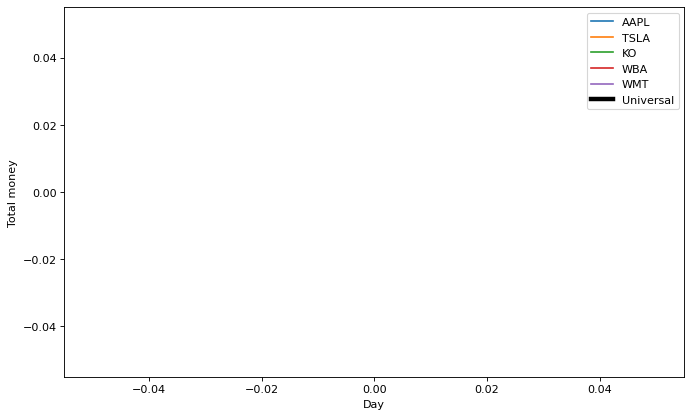

In [44]:
## compare buy and hold to universal portfolio

plt.figure(num=None, figsize=(10, 6), dpi=80, facecolor='w', edgecolor='k')


for ii in range(buy_and_hold_money.shape[0]):
    plt.plot(buy_and_hold_money[ii, :], label = tickers[ii])
    
plt.plot(total_money_trace, 'black', label="Universal", linewidth=4)
plt.legend()
plt.xlabel("Day")
plt.ylabel("Total money")
#plt.savefig("./unistock_portfolio_returns.pdf")
plt.show()

Remarque : on ne bouge pas beaucoup du portefeuille uniforme en réalité  !!! 

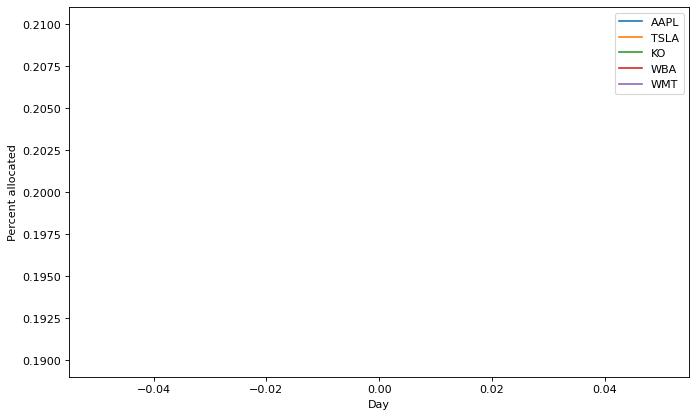

In [45]:
## look at evolution of universal portfolio over time

plt.figure(num=None, figsize=(10, 6), dpi=80, facecolor='w', edgecolor='k')

used_portfolios = np.array(used_portfolios)

for ii in range(used_portfolios.shape[1]):
    
    plt.plot(used_portfolios[:, ii], label = tickers[ii])
    
plt.xlabel("Day")
plt.ylabel("Percent allocated")
plt.legend()
#plt.savefig("./allocation_UP.pdf")
plt.show()

Test sur des valeurs fictives 

In [46]:
def plot_returns(returns):
    T, d = returns.shape
    # Calculer les rendements cumulés
    cumulative_returns = np.multiply.accumulate(returns, axis=0)
    # Créer le graphique
    plt.figure(figsize=(10, 6))
    # Tracer chaque actif
    for i in range(d):
        plt.plot(cumulative_returns[:, i], label=f'Actif {i+1}')
    # Ajouter un titre et des légendes
    plt.title('Rendements cumulés des actifs')
    plt.xlabel('Pas de temps')
    plt.ylabel('Rendement cumulé')
    plt.legend(loc='upper left')
    plt.grid(True)
    # Afficher le graphique
    plt.show()

def generate_gaussian_returns(d, T, mean=0, std=1):
    '''
    Génère une matrice de rendements gaussiens pour d actifs et T pas de temps.
    Retourne: numpy.ndarray: Une matrice de taille (T, d) contenant les rendements
    '''
    returns = np.random.normal(loc=mean, scale=std, size=(T, d))
    return 1 + returns



Constat assez surprenant : Universal Portfolio met énormément de temps à sortir du portefeuille uniforme !! Il est vraiment très peu sensible au changement 

En fait, Universal Portfolio s'intéresse à la croissance linéaire des rendements. Ainsi pour qu'un actif "prédomine" dans l'allocation, il faut qu'il croisse exponentiellement en valeur. 

Idée d'amélioration :  Ajouter des poids (exponential moving average) -> On alloue plus d'importance aux jours passés il y a peu de temps 

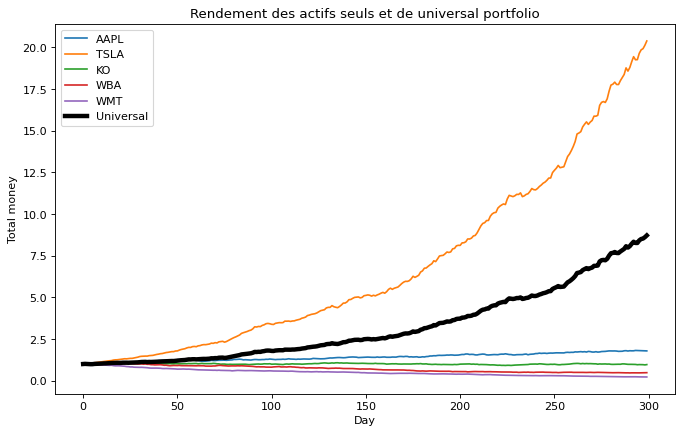

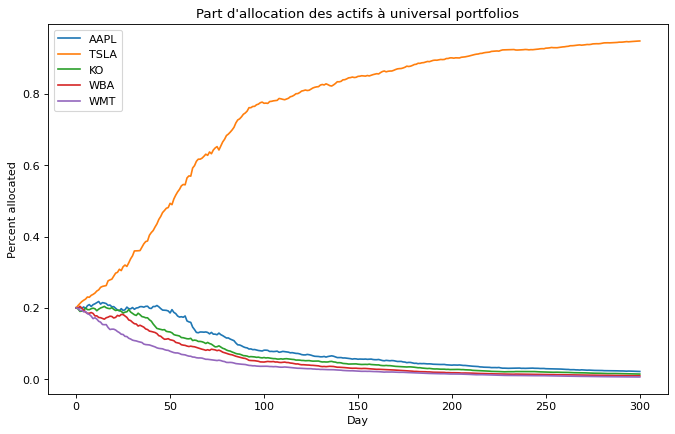

In [48]:
d = 5       # actifs
T = 300    # pas de temps

# Générer des returns 

returns = generate_gaussian_returns(d, T, [0.002, 0.01, 0, -0.002, -0.004], 0.01)

## RUN UNIVERSAL PORTFOLIO

initial_money = 1
curr_portfolio = np.ones(d) * 1.0 / d # uniform portfolio
used_portfolios = []
money_per_stock = []
total_money_trace = []
money_per_stock.append(curr_portfolio * initial_money)
used_portfolios.append(curr_portfolio)

data = returns.transpose()

## run the algorithm
for tt in range(T):
    
    ## calculate returns
    curr_return = np.multiply(data[:, tt], money_per_stock)
    total_money = np.sum(curr_return)
    total_money_trace.append(total_money)
    
    ## compute the updated portfolio
    portfolio_weights = np.array([np.exp(portfolio_wealth(x, data[:, :tt+1])) for x in list(all_portfolios)])
    weighted_portfolio = np.dot(portfolio_weights, all_portfolios)
    curr_portfolio = weighted_portfolio / np.sum(portfolio_weights)
    used_portfolios.append(curr_portfolio)
    
    ## rebalance the money
    money_per_stock = curr_portfolio * total_money
    

    
## compute the best "buy and hold" strategy
buy_and_hold_returns = np.prod(data, axis=1)
    
## compute the best constant rebalanced portfolio in hindsight

# plot_returns(returns)

## compare buy and hold to universal portfolio

plt.figure(num=None, figsize=(10, 6), dpi=80, facecolor='w', edgecolor='k')

buy_and_hold_money = initial_money * np.cumprod(data, axis=1)
for ii in range(buy_and_hold_money.shape[0]):
    plt.plot(buy_and_hold_money[ii, :], label = tickers[ii])
    
plt.plot(total_money_trace, 'black', label="Universal", linewidth=4)
plt.legend()
plt.xlabel("Day")
plt.ylabel("Total money")
plt.title("Rendement des actifs seuls et de universal portfolio")
#plt.savefig("./univ_port_returns2.pdf")
plt.show()

## look at evolution of universal portfolio over time

plt.figure(num=None, figsize=(10, 6), dpi=80, facecolor='w', edgecolor='k')

used_portfolios = np.array(used_portfolios)

for ii in range(used_portfolios.shape[1]):
    
    plt.plot(used_portfolios[:, ii], label = tickers[ii])
    
plt.xlabel("Day")
plt.ylabel("Percent allocated")
plt.legend()
plt.title("Part d'allocation des actifs à universal portfolios")
#plt.savefig("./univ_portfolio2.pdf")
plt.show()


On va essayer d'inclure une exp moving average dans le calcul des returns.

In [49]:
print(data[:, :tt+1])
print(len(data[:, 200:tt+1][0]))

[[1.00356639 1.01259246 0.98808716 ... 0.99581635 0.997482   1.00073995]
 [1.02074411 1.02212766 1.00414114 ... 1.00358871 1.0103042  1.0127298 ]
 [0.99831853 0.99168361 0.99455296 ... 0.99703232 0.98642081 1.01864271]
 [1.00301244 1.0219014  0.9819792  ... 0.99564014 1.02654343 0.99692119]
 [1.00166517 0.99455676 0.99424256 ... 0.99136038 0.99196992 0.99394544]]
100
